In [2]:
import numpy as np
import pandas as pd
from glob import glob
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from pathlib import Path

def load_and_balance_data(label_pattern, image_pattern):
    """Load and balance signal/background data from parquet files"""
    label_files = sorted(Path(".").glob(label_pattern))
    image_files = sorted(Path(".").glob(image_pattern))
    
    all_images, all_labels = [], []
    
    for label_file, image_file in zip(label_files, image_files):
        print(f"Processing: {label_file.name} & {image_file.name}")
        
        labels_df = pd.read_parquet(label_file)
        images_df = pd.read_parquet(image_file)
        
        # Create binary label
        labels_df["is_signal"] = labels_df["pt"].abs() > 0.2
        
        # Balance dataset by undersampling majority class
        n_signal = labels_df["is_signal"].sum()
        n_background = (~labels_df["is_signal"]).sum()
        n_samples = min(n_signal, n_background)
        
        # Sample equal amounts and shuffle
        balanced_labels = pd.concat([
            labels_df[labels_df["is_signal"]].sample(n=n_samples, random_state=42),
            labels_df[~labels_df["is_signal"]].sample(n=n_samples, random_state=42)
        ]).sample(frac=1, random_state=42)
        
        # Select corresponding images
        balanced_images = images_df.loc[balanced_labels.index]
        
        all_images.append(balanced_images.reset_index(drop=True))
        all_labels.append(balanced_labels.reset_index(drop=True))
    
    # Concatenate all files
    images = pd.concat(all_images, axis=0, ignore_index=True)
    labels = pd.concat(all_labels, axis=0, ignore_index=True)
    
    # Reshape images
    images = images.values.reshape(-1, 20, 13, 21)
    
    return images, labels

# Usage
images, labels = load_and_balance_data(
    "data/7331128/labels/labels_d1730?.parquet",
    "data/7331128/recon3D/recon3D_d1730?.parquet"
)

print(f"Loaded {images.shape[0]} balanced events.")

ValueError: No objects to concatenate

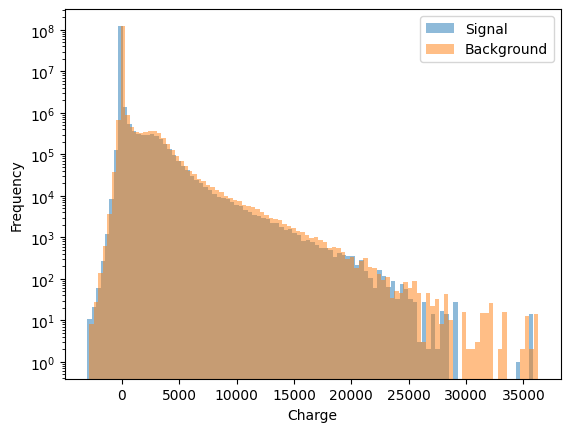

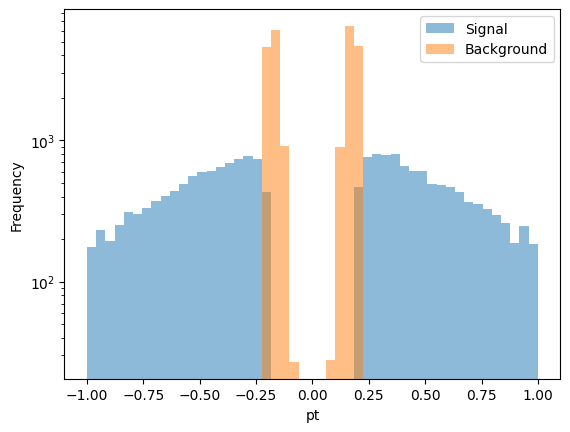

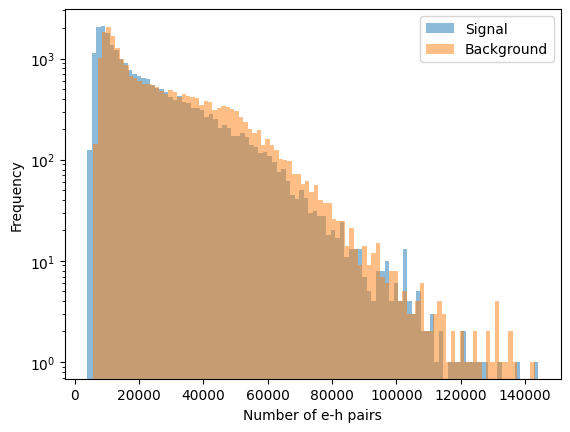

In [124]:
plt.hist(images[labels['is_signal']].flatten(), bins=100, alpha=0.5, label='Signal')
plt.hist(images[~labels['is_signal']].flatten(), bins=100, alpha=0.5, label='Background')
plt.xlabel('Charge')
plt.ylabel('Frequency')
plt.yscale('log')
plt.legend()
plt.show()

plt.hist(labels['pt'][labels['is_signal']], bins=np.linspace(-1, 1, 50), alpha=0.5, label='Signal')
plt.hist(labels['pt'][~labels['is_signal']], bins=np.linspace(-1, 1, 50), alpha=0.5, label='Background')
plt.legend()
plt.xlabel('pt')
plt.ylabel('Frequency')
plt.yscale('log')
plt.show()

plt.hist(labels['number_eh_pairs'][labels['is_signal']], bins=100, alpha=0.5, label='Signal')
plt.hist(labels['number_eh_pairs'][~labels['is_signal']], bins=100, alpha=0.5, label='Background')
plt.legend()
plt.xlabel('Number of e-h pairs')
plt.ylabel('Frequency')
plt.yscale('log')
plt.show()



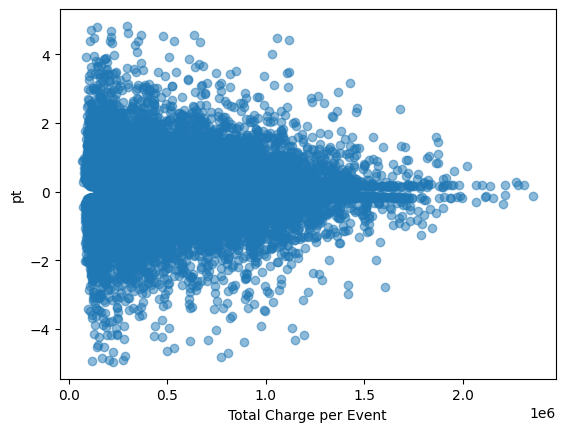

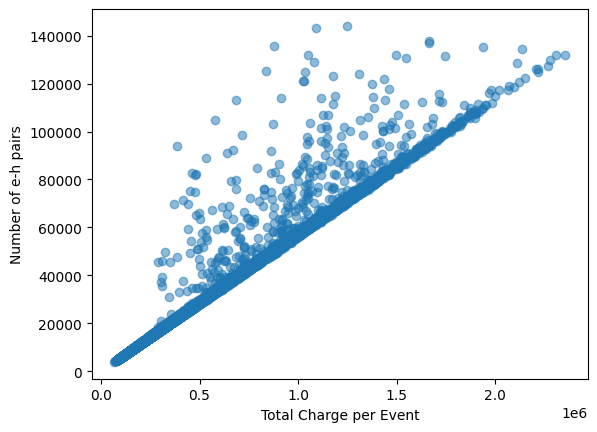

In [ ]:
charge_per_image = images.sum(axis=(1,2,3))
plt.scatter(charge_per_image, labels['pt'], alpha=0.5)
plt.xlabel('Total Charge per Event')
plt.ylabel('pt')
plt.show()

plt.scatter(charge_per_image, labels['number_eh_pairs'], alpha=0.5)
plt.xlabel('Total Charge per Event')
plt.ylabel('Number of e-h pairs')
plt.show()


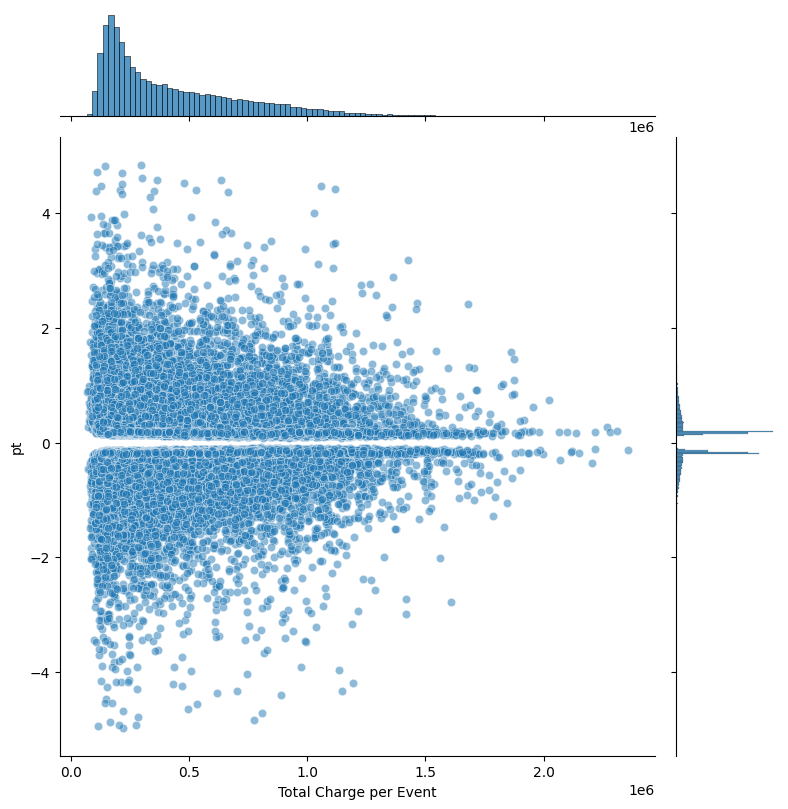

In [ ]:
import seaborn as sns

charge_per_image = images.sum(axis=(1,2,3))

g = sns.jointplot(x=charge_per_image, y=labels['pt'], 
                  alpha=0.5, height=8)
g.set_axis_labels('Total Charge per Event', 'pt')
plt.show()


AttributeError: PolyCollection.set() got an unexpected keyword argument 'cbar'

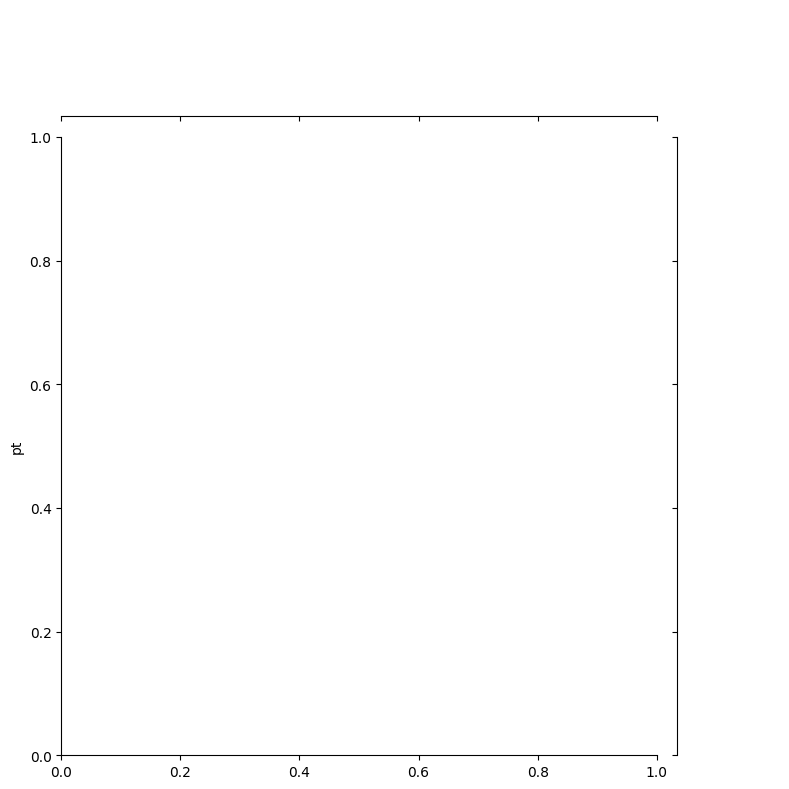

In [131]:
import seaborn as sns
from matplotlib.colors import LogNorm
import matplotlib.pyplot as plt

g = sns.jointplot(x=charge_per_image, y=labels['pt'], 
                  kind='hex', height=8, 
                  cmap='YlOrRd',  # White to yellow to red
                  joint_kws={'norm': LogNorm(), 'gridsize': 30, 'mincnt': 1},
                  cbar=True)
g.set_axis_labels('Total Charge per Event', 'pt')
plt.show()

Animation 0:




Animation 1:




Animation 2:




Animation 3:




Animation 4:




Animation 5:




Animation 6:




Animation 7:




Animation 8:




Animation 9:


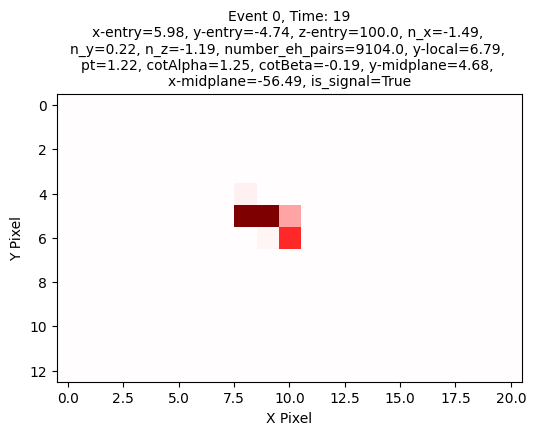

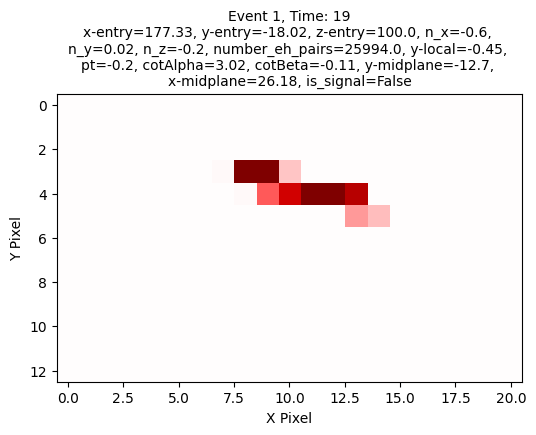

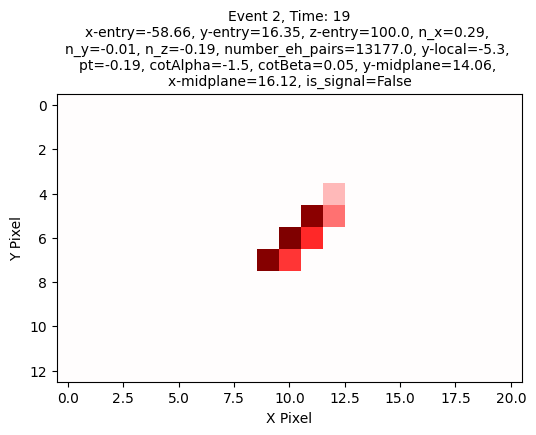

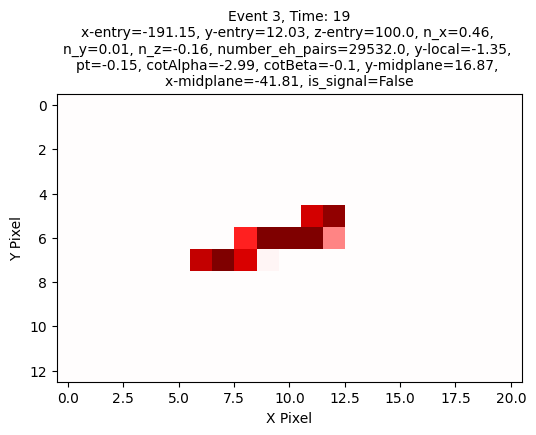

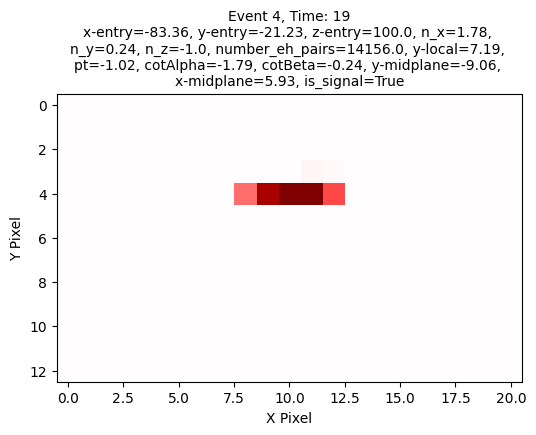

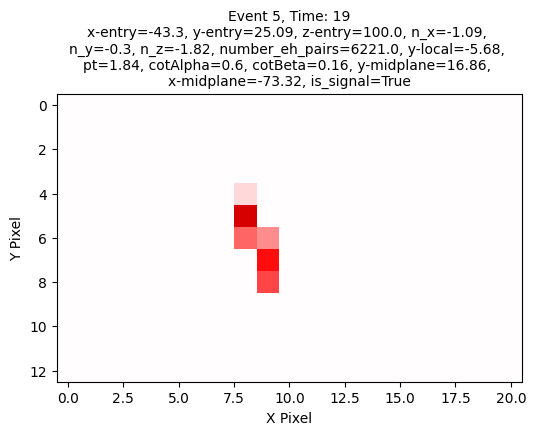

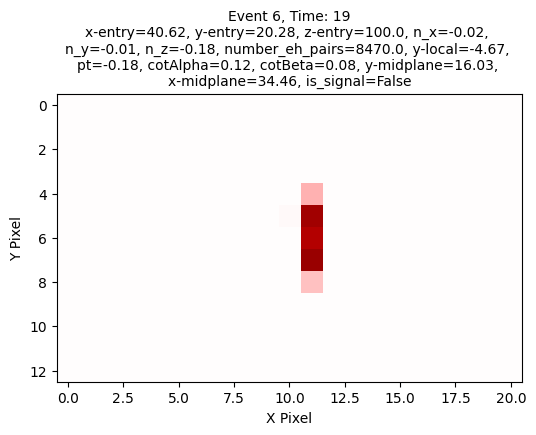

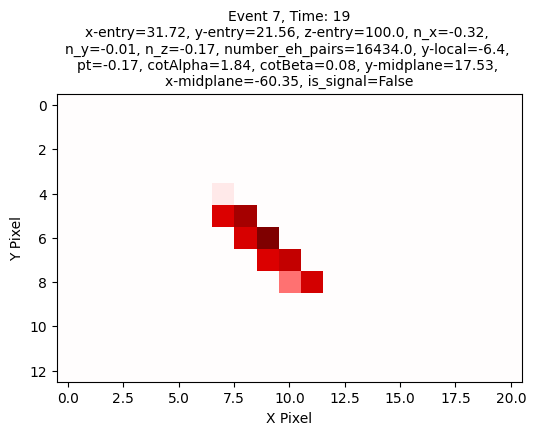

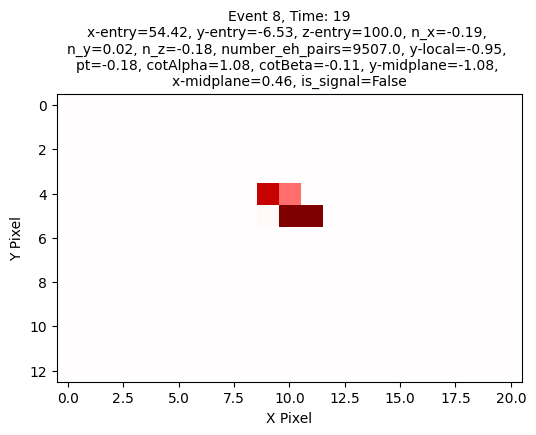

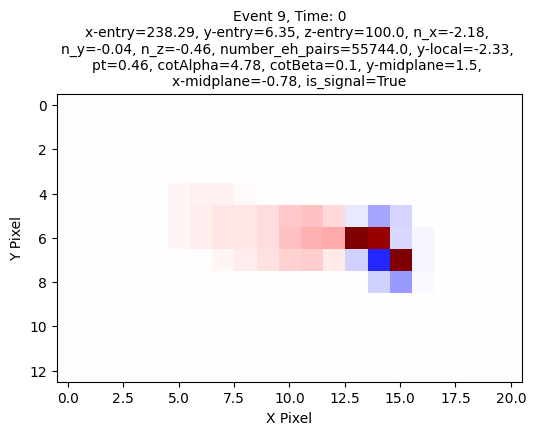

In [132]:
from matplotlib.colors import TwoSlopeNorm
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import numpy as np

# Calculate percentiles once
vmax = np.percentile(np.abs(images), 99)

n_events = 10
animations = []

for event_idx in range(n_events):
    fig, ax = plt.subplots(figsize=(6, 5))
    
    def update(frame, idx=event_idx):  # Capture event_idx in closure
        ax.clear()
        ax.imshow(images[idx, frame], cmap='seismic', norm=TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax))
        ax.set_xlabel('X Pixel')
        ax.set_ylabel('Y Pixel')
        labels_str = ""
        for i, col in enumerate(labels.columns):
            val = labels.iloc[idx][col]
            if isinstance(val, float):
                labels_str += f"{col}={round(val, 2)}, "
            else:
                labels_str += f"{col}={val}, "
            if i % 4 == 3:
                labels_str += "\n"
        labels_str = labels_str.rstrip(', ')
        ax.set_title(f'Event {idx}, Time: {frame}\n{labels_str}', fontsize=10)
        return ax
    
    ani = FuncAnimation(fig, update, frames=images_.shape[1], interval=100, repeat=True)
    animations.append(ani)
    
    print(f"Animation {event_idx}:")
    display(HTML(ani.to_jshtml()))
    print("\n" + "="*80 + "\n")

In [133]:
# train-test split
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import TensorDataset

binary_labels = labels['is_signal'].astype(int).values

X_train, X_test, y_train, y_test = train_test_split(images, binary_labels, test_size=0.2, random_state=42, stratify=binary_labels)
print(f"X_train.shape = {X_train.shape}, X_test.shape = {X_test.shape}")
print(f"y_train distribution:\n{pd.Series(y_train).value_counts()}")
print(f"y_test distribution:\n{pd.Series(y_test).value_counts()}")

import numpy as np

def symlog_transform(x, linthresh=1.0):
    """Symmetric log transform that handles negative values and zeros"""
    return np.sign(x) * np.log1p(np.abs(x) / linthresh)

def inverse_symlog_transform(x, linthresh=1.0):
    """Inverse transform"""
    return np.sign(x) * linthresh * (np.exp(np.abs(x)) - 1)

# Apply to your data
linthresh = 10.0  # Tune this - values below this are ~linear
X_train_transformed = symlog_transform(X_train, linthresh=linthresh)
X_test_transformed = symlog_transform(X_test, linthresh=linthresh)

# Then standardize (zero mean, unit variance)
mean = X_train_transformed.mean()
std = X_train_transformed.std()
X_train_normalized = (X_train_transformed - mean) / std
X_test_normalized = (X_test_transformed - mean) / std

train_dataset = TensorDataset(
    torch.tensor(X_train_normalized, dtype=torch.float32).unsqueeze(1), 
    torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
)


X_train.shape = (37940, 20, 13, 21), X_test.shape = (9486, 20, 13, 21)
y_train distribution:
1    18970
0    18970
Name: count, dtype: int64
y_test distribution:
1    4743
0    4743
Name: count, dtype: int64


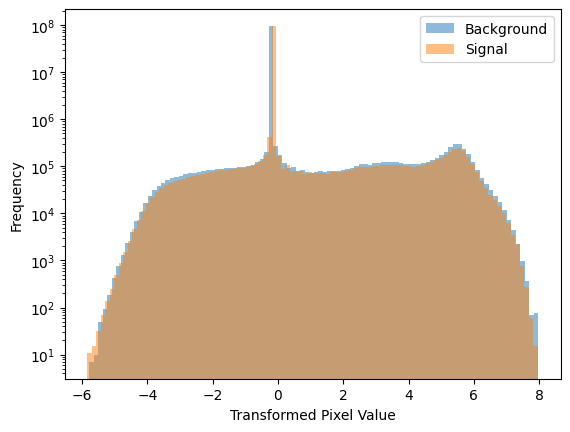

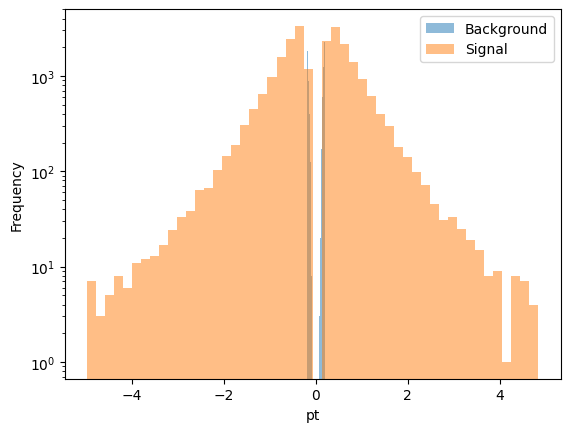

In [134]:
# histogram of transformed pixel values
X_bg = X_train_normalized[y_train == 0]
X_signal = X_train_normalized[y_train == 1]
plt.hist(X_bg.flatten(), bins=100, alpha=0.5, label='Background')
plt.hist(X_signal.flatten(), bins=100, alpha=0.5, label='Signal')
plt.xlabel('Transformed Pixel Value')
plt.ylabel('Frequency')
plt.yscale('log')
plt.legend()
plt.show()

# plot of pt distributions
plt.hist(labels[labels['is_signal']==0]['pt'], bins=50, alpha=0.5, label='Background')
plt.hist(labels[labels['is_signal']==1]['pt'], bins=50, alpha=0.5, label='Signal')
plt.xlabel('pt')
plt.ylabel('Frequency')
plt.yscale('log')
plt.legend()
plt.show()

In [145]:
# train a simple conv model in pytorch to classify signals vs backgrounds
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

model_conv3d = nn.Sequential(
    nn.Conv3d(1, 8, kernel_size=(3, 3, 3), padding=1),
    nn.ReLU(),
    nn.MaxPool3d((2, 2, 2)),
    nn.Conv3d(8, 16, kernel_size=(3, 3, 3), padding=1),
    nn.ReLU(),
    nn.MaxPool3d((2, 2, 2)),
    nn.Flatten(),
    nn.Linear(16 * 5 * 3 * 5, 64),
    nn.ReLU(),
    nn.Linear(64, 1),
    nn.Sigmoid()
)
criterion = nn.BCELoss()
optimizer_conv3d = optim.Adam(model_conv3d.parameters(), lr=0.001)

# print model summary
print(model_conv3d)
# total parameters
total_params = sum(p.numel() for p in model_conv3d.parameters())
print(f"Total parameters: {total_params}")

Sequential(
  (0): Conv3d(1, 8, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
  (1): ReLU()
  (2): MaxPool3d(kernel_size=(2, 2, 2), stride=(2, 2, 2), padding=0, dilation=1, ceil_mode=False)
  (3): Conv3d(8, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
  (4): ReLU()
  (5): MaxPool3d(kernel_size=(2, 2, 2), stride=(2, 2, 2), padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=1200, out_features=64, bias=True)
  (8): ReLU()
  (9): Linear(in_features=64, out_features=1, bias=True)
  (10): Sigmoid()
)
Total parameters: 80625


In [146]:
train_dataset = TensorDataset(torch.tensor(X_train_transformed, dtype=torch.float32).unsqueeze(1), torch.tensor(y_train, dtype=torch.float32).unsqueeze(1))
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_dataset = TensorDataset(torch.tensor(X_test_transformed, dtype=torch.float32).unsqueeze(1), torch.tensor(y_test, dtype=torch.float32).unsqueeze(1))
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

n_epochs = 10
for epoch in range(n_epochs):
    model_conv3d.train()
    running_loss = 0.0
    for inputs, labels in train_loader:
        optimizer_conv3d.zero_grad()
        outputs = model_conv3d(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_conv3d.step()
        running_loss += loss.item() * inputs.size(0)
    epoch_loss = running_loss / len(train_loader.dataset)
    print(f"Epoch {epoch+1}/{n_epochs}, Training Loss: {epoch_loss:.4f}")
    
    model_conv3d.eval()
    val_loss = 0.0
    with torch.no_grad():
        for inputs, labels in val_loader:
            outputs = model_conv3d(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * inputs.size(0)
    val_epoch_loss = val_loss / len(val_loader.dataset)
    print(f"Epoch {epoch+1}/{n_epochs}, Validation Loss: {val_epoch_loss:.4f}")
    


Epoch 1/10, Training Loss: 0.6859
Epoch 1/10, Validation Loss: 0.6823
Epoch 2/10, Training Loss: 0.6820
Epoch 2/10, Validation Loss: 0.6794
Epoch 3/10, Training Loss: 0.6766
Epoch 3/10, Validation Loss: 0.6794
Epoch 4/10, Training Loss: 0.6702
Epoch 4/10, Validation Loss: 0.6679
Epoch 5/10, Training Loss: 0.6598
Epoch 5/10, Validation Loss: 0.6601
Epoch 6/10, Training Loss: 0.6500
Epoch 6/10, Validation Loss: 0.6564
Epoch 7/10, Training Loss: 0.6423
Epoch 7/10, Validation Loss: 0.6631
Epoch 8/10, Training Loss: 0.6368
Epoch 8/10, Validation Loss: 0.6525
Epoch 9/10, Training Loss: 0.6313
Epoch 9/10, Validation Loss: 0.6528
Epoch 10/10, Training Loss: 0.6284
Epoch 10/10, Validation Loss: 0.6544


In [150]:
# # train a minimal model (random forest)
from sklearn.ensemble import RandomForestClassifier
model_forest = RandomForestClassifier(n_estimators=100, random_state=42, verbose=1)
model_forest.fit(
    X_train_normalized.reshape(X_train_normalized.shape[0], -1), 
    y_train,
)


[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:   22.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:   44.7s finished


,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.2s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.3s finished


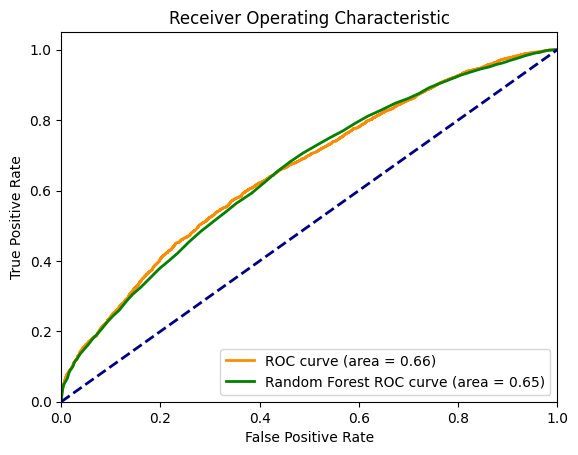

In [ ]:
# plot roc curve on test set
from sklearn.metrics import roc_curve, auc

def get_roc_curve(model, val_loader):
    if isinstance(model, RandomForestClassifier):
        y_scores = model.predict_proba(
            X_test_normalized.reshape(X_test_normalized.shape[0], -1)
        )[:, 1]
        fpr, tpr, thresholds = roc_curve(y_test, y_scores)
        roc_auc = auc(fpr, tpr)
        return fpr, tpr, roc_auc
    model.eval()
    all_outputs = []
    all_labels = []
    with torch.no_grad():
        for inputs, labels in val_loader:
            outputs = model(inputs)
            all_outputs.extend(outputs.squeeze().numpy())
            all_labels.extend(labels.squeeze().numpy())
    fpr, tpr, thresholds = roc_curve(all_labels, all_outputs)
    roc_auc = auc(fpr, tpr)
    return fpr, tpr, roc_auc

fpr, tpr, roc_auc = get_roc_curve(model_conv3d, val_loader)
fpr_forest, tpr_forest, roc_auc_forest = get_roc_curve(model_forest, val_loader)

import matplotlib.pyplot as plt

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Conv3d (area = %0.2f)' % roc_auc)
plt.plot(fpr_forest, tpr_forest, color='green', lw=2, label='Random Forest (area = %0.2f)' % roc_auc_forest)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# dataX = pd.read_parquet("7331128/negative-charge/recon8t*.csv")
# labels_df = pd.read_parquet("7331128/negative-charge/labels*.csv")
dataX = pd.read_parquet("7331128/negative-charge/")
labels_df = pd.read_parquet("7331128/negative-charge/")
reshaped_dataX = dataX.values.reshape((len(dataX), 20, 13, 21))

print(labels_df.iloc[0])
plt.imshow(reshaped_dataX[0, 0, :, :], cmap='coolwarm')  # first time-step
plt.show()
plt.imshow(reshaped_dataX[0, -1, :, :], cmap='coolwarm')  # last time-step
plt.show()